# HW11 - GPTQ quantization and knowledge distillation (submitted in the HW12 folder)

Run on a CUDA GPU (Colab T4 or better). Part 1 and Part 2 use different models and tasks and are kept separate.
Cell 1 states the personal parameters (Standing Requirement 0.1). Every number in `METRICS.md` is written by the last code cell from the saved results.

In [ ]:
# ---- Cell 0: install (run once). It restarts the runtime when done; then run from Cell 1 on. ----
# gptqmodel may replace torch with a newer CUDA build; Colab's preinstalled torchaudio/torchvision then mismatch
# and break transformers' imports. This notebook needs neither, so remove them.
%pip uninstall -y -q torchaudio torchvision
%pip install -q "transformers>=4.45" datasets accelerate optimum gptqmodel matplotlib scikit-learn
import os; os._exit(0)   # forces a runtime restart so the new packages are picked up (Colab shows "session crashed": expected)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
fastai 2.8.12 r

In [1]:
# ---- Cell 1: personal parameters (Standing Requirements 0.1) + setup ----
import os, sys, time, json, random, shutil, datetime, platform
import numpy as np, torch

SID4 = 3215
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10
print(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}")
# HW11 uses only SEED; HP_ID adds no extra temperature (assignment text).

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

assert torch.cuda.is_available(), "This notebook needs a CUDA GPU (latency / peak-memory / GPTQ kernels)."
DEV = "cuda:0"
OUT, FIG = "outputs", "figures"
for d in (OUT, FIG): os.makedirs(d, exist_ok=True)

LOG_PATH = "RUN_LOG.txt"
def log(*a):
    line = f"[{datetime.datetime.now().isoformat(timespec='seconds')}] " + " ".join(str(x) for x in a)
    print(line)
    with open(LOG_PATH, "a") as f: f.write(line + "\n")

import transformers, datasets
log("=== HW11 run start ===")
log(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}")
log(f"GPU={torch.cuda.get_device_name(0)} torch={torch.__version__} transformers={transformers.__version__} python={platform.python_version()}")

# ---- configuration (edit here only) ----
LLM_ID = "facebook/opt-125m"      # <- replace with the instructor-provided/approved base LLM
TEACHER_DIR = "teacher_model"     # <- folder with the fine-tuned BERT teacher
TEACHER_REPO = None               # <- set to the git URL of the repo that holds teacher_model/ (cloned automatically if the folder is missing)
STUDENT_ID = "distilbert/distilbert-base-uncased"
TEMPS = [1, 2, 4, 8]              # temperature sweep (see README: values were lost in the pasted brief)
ALPHAS = [0.3, 0.5, 0.7]          # weight on cross-entropy; KL weight = 1 - alpha
SWEEP_ALPHA = 0.5                 # alpha held fixed during the temperature sweep
EPOCHS, BATCH, LR, MAXLEN, VAL_N = 2, 64, 5e-5, 128, 5000

SID4=3215 SEED=3215 SLICE=215 HP_ID=5 CLS_A=5 CLS_B=2
[2026-11-25T01:21:50] === HW11 run start ===
[2026-11-25T01:21:50] SID4=3215 SEED=3215 SLICE=215 HP_ID=5 CLS_A=5 CLS_B=2
[2026-11-25T01:21:50] GPU=Tesla T4 torch=2.15.0+cu132 transformers=5.24.1 python=3.13.16


## Part 1 - GPTQ: base vs 4-bit quantized LLM (Wikitext2)
Same base model for both runs; Wikitext2 train is used for calibration only, Wikitext2 test for perplexity.

In [4]:
# ---- Part 1a: model revision, data, calibration, helpers ----
from huggingface_hub import HfApi
from transformers import AutoTokenizer, AutoModelForCausalLM, GPTQConfig
from datasets import load_dataset

LLM_REV = HfApi().model_info(LLM_ID).sha          # exact revision, pinned for both runs
log(f"Base LLM: {LLM_ID} revision={LLM_REV}")
tok = AutoTokenizer.from_pretrained(LLM_ID, revision=LLM_REV)
wt = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
SEQ = 2048 if "opt" in LLM_ID else 1024   # window for perplexity evaluation
CALIB = 1024    # calibration length: decode->re-tokenize adds BOS, so 2048-token windows overflow OPT's 2048 positions (CUDA assert)

# calibration: 128 random SEQ-token windows from the TRAIN split (seeded)
train_ids = tok("\n\n".join(wt["train"]["text"]), return_tensors="pt").input_ids[0]
g = np.random.RandomState(SEED)
starts = g.randint(0, len(train_ids) - CALIB - 1, size=128)
calib_texts = [tok.decode(train_ids[s:s+CALIB]) for s in starts]
test_ids = tok("\n\n".join(wt["test"]["text"]), return_tensors="pt").input_ids
log(f"calibration windows=128 x {CALIB} tokens; Wikitext2 test tokens={test_ids.shape[1]}")

@torch.no_grad()
def wikitext_ppl(model):
    model.eval(); nll, n = 0.0, 0
    for i in range(0, test_ids.shape[1] - 1, SEQ):
        ids = test_ids[:, i:i+SEQ].to(DEV)
        if ids.shape[1] < 2: break
        loss = model(ids, labels=ids).loss
        nll += loss.item() * (ids.shape[1] - 1); n += ids.shape[1] - 1
    return float(np.exp(nll / n)), nll / n

def bench(fn, warmup=10, runs=100):
    for _ in range(warmup): fn()
    torch.cuda.synchronize(); ts = []
    for _ in range(runs):
        t = time.perf_counter(); fn(); torch.cuda.synchronize(); ts.append((time.perf_counter() - t) * 1000)
    return float(np.percentile(ts, 50)), float(np.percentile(ts, 95))

def dir_mb(path):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 1e6

def measure_llm(model, name, path):
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    ppl, nll = wikitext_ppl(model)
    prompt = test_ids[:, :128].to(DEV)
    gen = lambda: model.generate(prompt, attention_mask=torch.ones_like(prompt), max_new_tokens=64, min_new_tokens=64, do_sample=False)
    pre = lambda: model(test_ids[:, :512].to(DEV))
    g50, g95 = bench(gen, 5, 50)
    p50, p95 = bench(pre, 10, 100)
    r = dict(name=name, ppl=ppl, nll=nll, gen_p50_ms=g50, gen_p95_ms=g95, prefill_p50_ms=p50, prefill_p95_ms=p95,
             peak_mem_gb=torch.cuda.max_memory_allocated() / 1e9, size_mb=dir_mb(path))
    log(name, json.dumps(r)); return r

[2026-11-25T01:24:26] Base LLM: facebook/opt-125m revision=27dcfa74d334bc871f3234de431e71c6eeba5dd6


config.json:   0%|          | 0.00/651 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/441 [00:00<?, ?B/s]

... (7 outputs left out)

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

[2026-11-25T01:24:45] calibration windows=128 x 1024 tokens; Wikitext2 test tokens=287645


In [5]:
# ---- Part 1b: base (fp16) measurement ----
BASE_DIR, Q_DIR = "ckpt/llm_base", "ckpt/llm_gptq4"
torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
base = AutoModelForCausalLM.from_pretrained(LLM_ID, revision=LLM_REV, dtype=torch.float16).to(DEV)
base.save_pretrained(BASE_DIR)                       # fp16 safetensors -> on-disk size
res_base = measure_llm(base, "Base LLM (fp16)", BASE_DIR)
del base; torch.cuda.empty_cache()

W1125 01:24:50.416000 7250 torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1125 01:24:50.487000 7250 torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  251MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  251MB            

model.safetensors: downloading bytes:           |  0.00B            

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[2026-11-25T01:25:45] Base LLM (fp16) {"name": "Base LLM (fp16)", "ppl": 27.661468398681446, "nll": 3.3200404122708154, "gen_p50_ms": 593.1802100000141, "gen_p95_ms": 815.0904545499542, "prefill_p50_ms": 11.430783499918107, "prefill_p95_ms": 14.3219713499775, "peak_mem_gb": 1.365654528, "size_mb": 250.501832}


In [6]:
# ---- Part 1c: GPTQ quantization (4-bit, group 128), then reload from disk and measure ----
set_seed()
t0 = time.time()
qcfg = GPTQConfig(bits=4, group_size=128, dataset=calib_texts, tokenizer=tok, desc_act=False, model_seqlen=CALIB)
qm = AutoModelForCausalLM.from_pretrained(LLM_ID, revision=LLM_REV, quantization_config=qcfg,
                                          dtype=torch.float16, device_map=DEV)
quant_s = time.time() - t0
qm.save_pretrained(Q_DIR); tok.save_pretrained(Q_DIR)
log(f"GPTQ quantization time {quant_s:.0f}s")
del qm; torch.cuda.empty_cache()
qm = AutoModelForCausalLM.from_pretrained(Q_DIR, dtype=torch.float16, device_map=DEV)
res_q = measure_llm(qm, "GPTQ 4-bit LLM", Q_DIR); res_q["quant_time_s"] = quant_s
del qm; torch.cuda.empty_cache()
json.dump(dict(model=LLM_ID, revision=LLM_REV, base=res_base, gptq=res_q), open(f"{OUT}/part1.json", "w"), indent=1)
import pandas as pd
display(pd.DataFrame([res_base, res_q]).set_index("name").round(3))


INFO  LogBar: headless/CI mode; progress animations disabled.                   
WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.
INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True' for memory saving.
INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           
INFO    ┌─────────────┐    ┌────────────────────────┐    ┌────────────┐    ┌─────────┐ │ GPT-QModel  │ -> │ ▓▓▓▓▓▓▓▓▓▓▓▓ 16bit     │ -> │ ▒▒▒▒ 8bit  │ -> │ ░░ 4bit │ └─────────────┘    └────────────────────────┘    └────────────┘    └─────────┘ GPT-QModel   : 7.12.2 Transformers : 5.24.1 Torch        : 2.15.0+cu132 Triton       : 3.9.0


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Quantizing model.decoder.layers blocks :   0%|          | 0/12 [00:00<?, ?it/s]

Quantizing layers inside the block:   0%|          | 0/6 [00:00<?, ?it/s]

INFO  GPTQ block update: compiling torch.ops JIT extension in `/root/.cache/gptqmodel/torch_extensions/gptq_block/934e6159c29e1ece`.
INFO  GPTQ block update: torch.ops JIT extension ready in 44s.                  


Quantizing layers inside the block:   0%|          | 0/6 [00:00<?, ?it/s]

... (15 outputs left out)

Loading weights:   0%|          | 0/412 [00:00<?, ?it/s]

[transformers] OPTForCausalLM LOAD REPORT from: ckpt/llm_gptq4
Key                                                            | Status  | 
---------------------------------------------------------------+---------+-
model.decoder.layers.{0...11}.self_attn.out_proj.qzeros_format | MISSING | 
model.decoder.layers.{0...11}.self_attn.k_proj.qzeros_format   | MISSING | 
model.decoder.layers.{0...11}.self_attn.q_proj.qzeros_format   | MISSING | 
model.decoder.layers.{0...11}.fc1.qzeros_format                | MISSING | 
model.decoder.layers.{0...11}.self_attn.v_proj.qzeros_format   | MISSING | 
model.decoder.layers.{0...11}.fc2.qzeros_format                | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


INFO  gc.collect() reclaimed 10151 objects in 0.386s                            
[2026-11-25T01:29:56] GPTQ 4-bit LLM {"name": "GPTQ 4-bit LLM", "ppl": 31.18310850164278, "nll": 3.4398765540305756, "gen_p50_ms": 1156.2839954999617, "gen_p95_ms": 1542.9275501998743, "prefill_p50_ms": 20.768685499888306, "prefill_p95_ms": 25.422097549903807, "peak_mem_gb": 1.23369728, "size_mb": 129.277734}


,ppl,nll,gen_p50_ms,gen_p95_ms,prefill_p50_ms,prefill_p95_ms,peak_mem_gb,size_mb,quant_time_s
name,,,,,,,,,
Base LLM (fp16),27.661,3.32,593.180,815.090,11.431,14.322,1.366,250.502,NaN
GPTQ 4-bit LLM,31.183,3.44,1156.284,1542.928,20.769,25.422,1.234,129.278,168.723


### Part 1 findings
*(Write after the run, from the table above: perplexity change, p50/p95 generation and prefill latency, peak memory, on-disk size, and why latency did or did not improve for a small model on this GPU.)*

## Part 2 - Knowledge distillation on AG News (BERT teacher -> DistilBERT student)
Teacher logits are extracted for **all 120,000** training samples. To select T and alpha without touching the test set, 5,000 training samples (seeded) are held out as validation; the students train on the remaining 115,000 using the cached teacher logits. Test accuracy is reported for every run, but selection uses validation accuracy.

In [3]:
# ---- Extract /content/teacher_model.7z and set TEACHER_DIR ----
%pip install -q py7zr
import os, glob, py7zr

ARCHIVE = "/content/teacher_model.7z"
assert os.path.isfile(ARCHIVE), f"{ARCHIVE} not found"
print("archive size (MB):", round(os.path.getsize(ARCHIVE) / 1e6, 1))

if not glob.glob("/content/teacher_extract/**/config.json", recursive=True):
    with py7zr.SevenZipFile(ARCHIVE) as z:
        z.extractall("/content/teacher_extract")

hits = [h for h in glob.glob("/content/teacher_extract/**/config.json", recursive=True) if "__MACOSX" not in h]
assert hits, "config.json not found after extraction"
TEACHER_DIR = os.path.dirname(hits[0])
assert os.path.isfile(os.path.join(TEACHER_DIR, "model.safetensors")), "model.safetensors missing"
print("TEACHER_DIR =", TEACHER_DIR, sorted(os.listdir(TEACHER_DIR)))

archive size (MB): 401.7
TEACHER_DIR = /content/teacher_extract/teacher_model ['__MACOSX', 'config.json', 'model.safetensors', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.txt']


In [7]:
import os, glob
print("TEACHER_DIR" in globals(), glob.glob("/content/teacher_extract/**/config.json", recursive=True))
print("part1.json:", os.path.exists("outputs/part1.json"))

True ['/content/teacher_extract/teacher_model/config.json']
part1.json: True


In [10]:
import os, glob
TEACHER_DIR = os.path.dirname([h for h in glob.glob("/content/teacher_extract/**/config.json", recursive=True) if "__MACOSX" not in h][0])
print(TEACHER_DIR, os.path.isfile(TEACHER_DIR + "/model.safetensors"))

/content/teacher_extract/teacher_model True


In [12]:
# ---- Part 2a: data + teacher logits for ALL training samples ----
import torch.nn.functional as F
from transformers import AutoModelForSequenceClassification
ag = load_dataset("fancyzhx/ag_news"); CLASSES = ag["train"].features["label"].names
tr_text, tr_y = list(ag["train"]["text"]), np.array(ag["train"]["label"])
te_text, te_y = list(ag["test"]["text"]), np.array(ag["test"]["label"])
log(f"AG News train={len(tr_text)} test={len(te_text)} classes={CLASSES}")

def encode(tk, texts):
    return tk(texts, truncation=True, max_length=MAXLEN, return_token_type_ids=False)["input_ids"]

def collate_ids(tk):
    def f(batch):
        ids = [b[0] for b in batch]
        out = tk.pad({"input_ids": ids}, return_tensors="pt")
        return out["input_ids"], out["attention_mask"], torch.tensor([b[1] for b in batch])
    return f

if not os.path.isfile(os.path.join(TEACHER_DIR, "config.json")) and TEACHER_REPO:
    import subprocess, glob   # clone the repo (git-lfs needed for large weights) and locate teacher_model/
    subprocess.run(["git", "lfs", "install"], check=False); subprocess.run(["git", "clone", "--depth", "1", TEACHER_REPO, "teacher_repo"], check=True)
    hits = glob.glob("teacher_repo/**/teacher_model", recursive=True)
    if hits: TEACHER_DIR = hits[0]
    log("teacher_model located at", TEACHER_DIR, os.listdir(TEACHER_DIR))
if not os.path.isfile(os.path.join(TEACHER_DIR, "config.json")):
    raise FileNotFoundError(f"'{TEACHER_DIR}/config.json' not found on this machine. Upload the instructor's teacher_model folder "
        "to the Colab filesystem (Files panel -> upload, or drive.mount + copy) and set TEACHER_DIR in cell 1 to its path, then re-run from here.")
t_tok = AutoTokenizer.from_pretrained(TEACHER_DIR)
teacher = AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).to(DEV).eval()
log("teacher:", teacher.config.architectures, "params", sum(p.numel() for p in teacher.parameters()))

@torch.no_grad()
def predict_logits(model, tk, texts, bs=256):
    ids = encode(tk, texts); order = np.argsort([len(x) for x in ids]); out = np.zeros((len(ids), 4), np.float32)
    for i in range(0, len(ids), bs):
        idx = order[i:i+bs]
        b = tk.pad({"input_ids": [ids[j] for j in idx]}, return_tensors="pt").to(DEV)
        with torch.autocast("cuda", dtype=torch.float16):
            out[idx] = model(**b).logits.float().cpu().numpy()
    return out

t0 = time.time()
T_train_logits = predict_logits(teacher, t_tok, tr_text)
T_test_logits = predict_logits(teacher, t_tok, te_text)
np.save(f"{OUT}/teacher_train_logits.npy", T_train_logits)
tacc = float((T_test_logits.argmax(1) == te_y).mean())
log(f"teacher logits extracted for {len(tr_text)} train samples in {time.time()-t0:.0f}s; teacher test acc={tacc:.4f}; train acc={(T_train_logits.argmax(1)==tr_y).mean():.4f}")
assert tacc > 0.85, "Teacher label order/tokenizer mismatch? accuracy is too low."

[2026-11-25T01:33:27] AG News train=120000 test=7600 classes=['World', 'Sports', 'Business', 'Sci/Tech']


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[2026-11-25T01:33:28] teacher: ['BertForSequenceClassification'] params 109485316
[2026-11-25T01:35:34] teacher logits extracted for 120000 train samples in 127s; teacher test acc=0.9443; train acc=0.9895


In [13]:
# ---- Part 2b: distillation loss + training function ----
from torch.utils.data import DataLoader
from transformers import get_linear_schedule_with_warmup
s_tok = AutoTokenizer.from_pretrained(STUDENT_ID)
s_tr_ids, s_te_ids = encode(s_tok, tr_text), encode(s_tok, te_text)

perm = np.random.RandomState(SEED).permutation(len(tr_text))
val_idx, fit_idx = perm[:VAL_N], perm[VAL_N:]

def distill_loss(s_logits, t_logits, y, T, alpha):
    ce = F.cross_entropy(s_logits, y)
    kd = F.kl_div(F.log_softmax(s_logits / T, -1), F.softmax(t_logits / T, -1), reduction="batchmean") * (T * T)
    return alpha * ce + (1 - alpha) * kd, ce, kd

@torch.no_grad()
def eval_ids(model, ids, y, bs=256):
    model.eval(); order = np.argsort([len(x) for x in ids]); pred = np.zeros(len(ids), int)
    for i in range(0, len(ids), bs):
        idx = order[i:i+bs]
        b = s_tok.pad({"input_ids": [ids[j] for j in idx]}, return_tensors="pt").to(DEV)
        with torch.autocast("cuda", dtype=torch.float16):
            pred[idx] = model(**b).logits.argmax(-1).cpu().numpy()
    return float((pred == y).mean()), pred

def train_student(T, alpha, tag):
    set_seed()                                           # same seed -> same init of the classifier head and same batch order
    model = AutoModelForSequenceClassification.from_pretrained(STUDENT_ID, num_labels=4).to(DEV)   # fresh from pretrained
    ds = [(s_tr_ids[i], int(tr_y[i]), T_train_logits[i]) for i in fit_idx]
    def coll(batch):
        o = s_tok.pad({"input_ids": [b[0] for b in batch]}, return_tensors="pt")
        return o["input_ids"], o["attention_mask"], torch.tensor([b[1] for b in batch]), torch.tensor(np.stack([b[2] for b in batch]))
    gen = torch.Generator().manual_seed(SEED)
    dl = DataLoader(ds, batch_size=BATCH, shuffle=True, collate_fn=coll, generator=gen)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total = EPOCHS * len(dl); sch = get_linear_schedule_with_warmup(opt, int(0.06 * total), total)
    scaler = torch.amp.GradScaler(); hist = []; step = 0; t0 = time.time()
    run = dict(tot=0., ce=0., kd=0., n=0)
    for ep in range(EPOCHS):
        model.train()
        for ids, am, y, tl in dl:
            ids, am, y, tl = ids.to(DEV), am.to(DEV), y.to(DEV), tl.to(DEV)
            with torch.autocast("cuda", dtype=torch.float16):
                sl = model(input_ids=ids, attention_mask=am).logits
            loss, ce, kd = distill_loss(sl.float(), tl, y, T, alpha)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sch.step(); step += 1
            for k, v in (("tot", loss), ("ce", ce), ("kd", kd)): run[k] += v.item()
            run["n"] += 1
            if step % 200 == 0:
                rec = dict(step=step, epoch=ep + step / len(dl) - ep, loss=run["tot"]/run["n"], ce=run["ce"]/run["n"], kd=run["kd"]/run["n"])
                hist.append(rec); run = dict(tot=0., ce=0., kd=0., n=0)
                if step % 1000 == 0: log(f"[{tag}] step {step}/{total} loss={rec['loss']:.4f} ce={rec['ce']:.4f} kd={rec['kd']:.4f}")
        vacc, _ = eval_ids(model, [s_tr_ids[i] for i in val_idx], tr_y[val_idx])
        log(f"[{tag}] epoch {ep+1}/{EPOCHS} val_acc={vacc:.4f}")
    tacc_s, _ = eval_ids(model, s_te_ids, te_y)
    r = dict(tag=tag, T=T, alpha=alpha, val_acc=vacc, test_acc=tacc_s, train_s=time.time() - t0, history=hist)
    log(f"[{tag}] DONE T={T} alpha={alpha} val_acc={vacc:.4f} test_acc={tacc_s:.4f} time={r['train_s']:.0f}s")
    return model, r

BEST = dict(val=-1)
def run_one(T, alpha, tag):
    global BEST
    model, r = train_student(T, alpha, tag)
    if r["val_acc"] > BEST["val"]:                       # keep only the best-by-validation student on disk
        shutil.rmtree("ckpt/student_best", ignore_errors=True); model.save_pretrained("ckpt/student_best"); s_tok.save_pretrained("ckpt/student_best")
        BEST = dict(val=r["val_acc"], T=T, alpha=alpha, tag=tag)
    del model; torch.cuda.empty_cache(); return r

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [14]:
# ---- Part 2c: temperature sweep (alpha fixed), each student re-initialised from the same checkpoint ----
sweepT = [run_one(T, SWEEP_ALPHA, f"T={T},a={SWEEP_ALPHA}") for T in TEMPS]
bestT = max(sweepT, key=lambda r: r["val_acc"])["T"]
log(f"best temperature by validation accuracy: T={bestT}")
display(pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in sweepT]).round(4))

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[2026-11-25T01:52:12] [T=1,a=0.5] step 1000/3594 loss=0.1860 ce=0.2037 kd=0.1684
[2026-11-25T01:54:26] [T=1,a=0.5] epoch 1/2 val_acc=0.9388
[2026-11-25T01:55:00] [T=1,a=0.5] step 2000/3594 loss=0.1121 ce=0.1260 kd=0.0982
[2026-11-25T01:57:49] [T=1,a=0.5] step 3000/3594 loss=0.1004 ce=0.1140 kd=0.0867
[2026-11-25T01:59:31] [T=1,a=0.5] epoch 2/2 val_acc=0.9434
[2026-11-25T01:59:33] [T=1,a=0.5] DONE T=1 alpha=0.5 val_acc=0.9434 test_acc=0.9457 time=599s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (10 outputs left out)

[2026-11-25T02:23:52] [T=8,a=0.5] step 1000/3594 loss=0.5029 ce=0.2625 kd=0.7433
[2026-11-25T02:26:07] [T=8,a=0.5] epoch 1/2 val_acc=0.9410
[2026-11-25T02:26:41] [T=8,a=0.5] step 2000/3594 loss=0.2858 ce=0.1607 kd=0.4110
[2026-11-25T02:29:29] [T=8,a=0.5] step 3000/3594 loss=0.2604 ce=0.1515 kd=0.3693
[2026-11-25T02:31:11] [T=8,a=0.5] epoch 2/2 val_acc=0.9454
[2026-11-25T02:31:14] [T=8,a=0.5] DONE T=8 alpha=0.5 val_acc=0.9454 test_acc=0.9461 time=609s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[2026-11-25T02:31:47] best temperature by validation accuracy: T=8


,tag,T,alpha,val_acc,test_acc,train_s
0,"T=1,a=0.5",1,0.5,0.9434,0.9457,599.0250
1,"T=2,a=0.5",2,0.5,0.9442,0.9454,607.0958
2,"T=4,a=0.5",4,0.5,0.9446,0.9470,607.6556
3,"T=8,a=0.5",8,0.5,0.9454,0.9461,609.2356


In [15]:
# ---- Part 2d: loss-weighting sweep at the best temperature ----
sweepA = [run_one(bestT, a, f"T={bestT},a={a}") for a in ALPHAS]
bestA = max(sweepA, key=lambda r: r["val_acc"])["alpha"]
log(f"best alpha at T={bestT}: {bestA}; overall best student: {BEST}")
display(pd.DataFrame([{k: v for k, v in r.items() if k != "history"} for r in sweepA]).round(4))
json.dump(dict(sweepT=sweepT, sweepA=sweepA, best=BEST, teacher_test_acc=tacc), open(f"{OUT}/part2_sweeps.json", "w"), indent=1)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[2026-11-25T02:34:33] [T=8,a=0.3] step 1000/3594 loss=0.5932 ce=0.2712 kd=0.7313
[2026-11-25T02:36:49] [T=8,a=0.3] epoch 1/2 val_acc=0.9416
[2026-11-25T02:37:23] [T=8,a=0.3] step 2000/3594 loss=0.3315 ce=0.1657 kd=0.4025
[2026-11-25T02:40:11] [T=8,a=0.3] step 3000/3594 loss=0.3125 ce=0.1643 kd=0.3760
[2026-11-25T02:41:53] [T=8,a=0.3] epoch 2/2 val_acc=0.9472
[2026-11-25T02:41:55] [T=8,a=0.3] DONE T=8 alpha=0.3 val_acc=0.9472 test_acc=0.9445 time=607s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[2026-11-25T02:44:52] [T=8,a=0.5] step 1000/3594 loss=0.5029 ce=0.2625 kd=0.7433
[2026-11-25T02:47:07] [T=8,a=0.5] epoch 1/2 val_acc=0.9410
[2026-11-25T02:47:42] [T=8,a=0.5] step 2000/3594 loss=0.2858 ce=0.1607 kd=0.4110
[2026-11-25T02:50:30] [T=8,a=0.5] step 3000/3594 loss=0.2604 ce=0.1515 kd=0.3693
[2026-11-25T02:52:11] [T=8,a=0.5] epoch 2/2 val_acc=0.9454
[2026-11-25T02:52:14] [T=8,a=0.5] DONE T=8 alpha=0.5 val_acc=0.9454 test_acc=0.9461 time=609s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[2026-11-25T02:55:02] [T=8,a=0.7] step 1000/3594 loss=0.4043 ce=0.2494 kd=0.7658
[2026-11-25T02:57:17] [T=8,a=0.7] epoch 1/2 val_acc=0.9408
[2026-11-25T02:57:51] [T=8,a=0.7] step 2000/3594 loss=0.2398 ce=0.1541 kd=0.4400
[2026-11-25T03:00:40] [T=8,a=0.7] step 3000/3594 loss=0.2152 ce=0.1416 kd=0.3868
[2026-11-25T03:02:22] [T=8,a=0.7] epoch 2/2 val_acc=0.9462
[2026-11-25T03:02:24] [T=8,a=0.7] DONE T=8 alpha=0.7 val_acc=0.9462 test_acc=0.9464 time=609s
[2026-11-25T03:02:25] best alpha at T=8: 0.3; overall best student: {'val': 0.9472, 'T': 8, 'alpha': 0.3, 'tag': 'T=8,a=0.3'}


,tag,T,alpha,val_acc,test_acc,train_s
0,"T=8,a=0.3",8,0.3,0.9472,0.9445,607.2831
1,"T=8,a=0.5",8,0.5,0.9454,0.9461,609.1508
2,"T=8,a=0.7",8,0.7,0.9462,0.9464,609.0778


Sample training log (first 6 logged windows of the first run):
{'step': 200, 'epoch': 0.1113, 'loss': 0.6164, 'ce': 0.6275, 'kd': 0.6054}
{'step': 400, 'epoch': 0.2226, 'loss': 0.2465, 'ce': 0.2599, 'kd': 0.2331}
{'step': 600, 'epoch': 0.3339, 'loss': 0.2221, 'ce': 0.2357, 'kd': 0.2085}
{'step': 800, 'epoch': 0.4452, 'loss': 0.198, 'ce': 0.213, 'kd': 0.1831}
{'step': 1000, 'epoch': 0.5565, 'loss': 0.186, 'ce': 0.2037, 'kd': 0.1684}
{'step': 1200, 'epoch': 0.6678, 'loss': 0.1803, 'ce': 0.1958, 'kd': 0.1648}


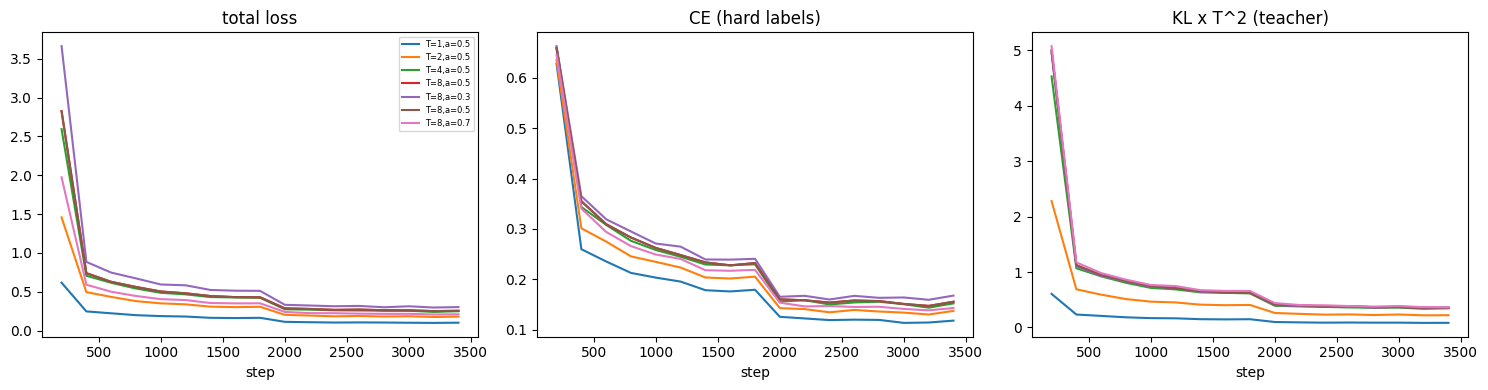

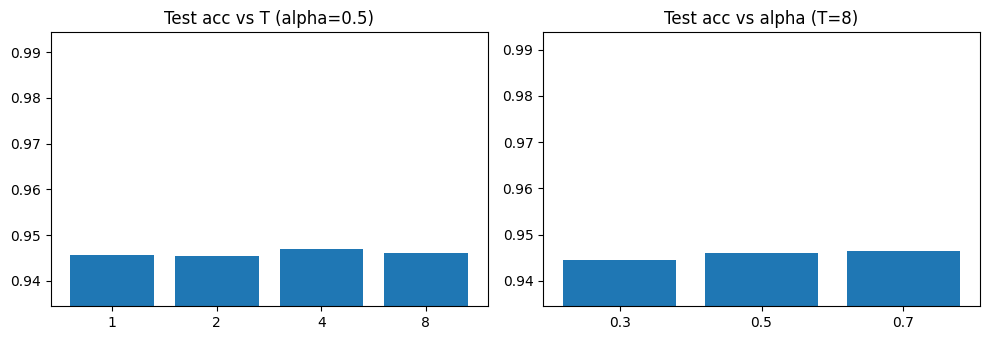

In [16]:
# ---- Part 2e: sample training log, loss trends, sweep figures ----
import matplotlib; import matplotlib.pyplot as plt
print("Sample training log (first 6 logged windows of the first run):")
for h in sweepT[0]["history"][:6]: print({k: round(v, 4) for k, v in h.items()})
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for r in sweepT + sweepA:
    st = [h["step"] for h in r["history"]]
    ax[0].plot(st, [h["loss"] for h in r["history"]], label=r["tag"]); ax[1].plot(st, [h["ce"] for h in r["history"]]); ax[2].plot(st, [h["kd"] for h in r["history"]])
for a_, t_ in zip(ax, ["total loss", "CE (hard labels)", "KL x T^2 (teacher)"]): a_.set_title(t_); a_.set_xlabel("step")
ax[0].legend(fontsize=6); plt.tight_layout(); plt.savefig(f"{FIG}/loss_trends.png", dpi=130); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].bar([str(r["T"]) for r in sweepT], [r["test_acc"] for r in sweepT]); ax[0].set_title(f"Test acc vs T (alpha={SWEEP_ALPHA})")
ax[1].bar([str(r["alpha"]) for r in sweepA], [r["test_acc"] for r in sweepA]); ax[1].set_title(f"Test acc vs alpha (T={bestT})")
for a_ in ax: a_.set_ylim(min(r["test_acc"] for r in sweepT + sweepA) - 0.01, None)
plt.tight_layout(); plt.savefig(f"{FIG}/sweeps.png", dpi=130); plt.show()

In [17]:
# ---- Part 2f: teacher vs best student - accuracy, latency, memory, size (same test set, same GPU) ----
def bench_cls(model, tk, texts, name, path):
    ids = encode(tk, texts); model.eval()
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    acc = None; pred = np.zeros(len(ids), int); order = np.argsort([len(x) for x in ids])
    with torch.no_grad():
        for i in range(0, len(ids), 128):
            idx = order[i:i+128]; b = tk.pad({"input_ids": [ids[j] for j in idx]}, return_tensors="pt").to(DEV)
            pred[idx] = model(**b).logits.argmax(-1).cpu().numpy()          # fp32 inference for fairness
    peak = torch.cuda.max_memory_allocated() / 1e9
    one = [tk.pad({"input_ids": [ids[j]]}, return_tensors="pt").to(DEV) for j in range(200)]
    k = iter(range(10**9))
    with torch.no_grad(): p50, p95 = bench(lambda: model(**one[next(k) % 200]), 20, 200)
    r = dict(name=name, acc=float((pred == te_y).mean()), p50_ms=p50, p95_ms=p95, peak_mem_gb=peak, size_mb=dir_mb(path),
             params_m=sum(p.numel() for p in model.parameters()) / 1e6)
    log(name, json.dumps(r)); return r, pred

teacher.save_pretrained("ckpt/teacher_copy")
rt, pred_t = bench_cls(teacher.float(), t_tok, te_text, "Teacher (BERT-base)", "ckpt/teacher_copy")
student = AutoModelForSequenceClassification.from_pretrained("ckpt/student_best").to(DEV)
rs, pred_s = bench_cls(student.float(), s_tok, te_text, f"Best distilled student (T={BEST['T']}, alpha={BEST['alpha']})", "ckpt/student_best")
json.dump(dict(teacher=rt, student=rs), open(f"{OUT}/part2_final.json", "w"), indent=1)
display(pd.DataFrame([rt, rs]).set_index("name").round(4))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[2026-11-25T03:03:10] Teacher (BERT-base) {"name": "Teacher (BERT-base)", "acc": 0.9443421052631579, "p50_ms": 8.632621999367984, "p95_ms": 10.419325150087387, "peak_mem_gb": 1.43190784, "size_mb": 437.965806, "params_m": 109.485316}


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[2026-11-25T03:03:24] Best distilled student (T=8, alpha=0.3) {"name": "Best distilled student (T=8, alpha=0.3)", "acc": 0.9444736842105264, "p50_ms": 4.417160499997408, "p95_ms": 5.279400300196355, "peak_mem_gb": 1.699738624, "size_mb": 268.55135, "params_m": 66.956548}


,acc,p50_ms,p95_ms,peak_mem_gb,size_mb,params_m
name,,,,,,
Teacher (BERT-base),0.9443,8.6326,10.4193,1.4319,437.9658,109.4853
"Best distilled student (T=8, alpha=0.3)",0.9445,4.4172,5.2794,1.6997,268.5514,66.9565


In [18]:
# ---- Part 2g: where compression hurts - per-class accuracy and 5 teacher-right / student-wrong examples ----
from sklearn.metrics import confusion_matrix
pc = lambda p: np.array([(p[te_y == c] == c).mean() for c in range(4)])
at, as_ = pc(pred_t), pc(pred_s); drop = at - as_; worst = int(drop.argmax())
display(pd.DataFrame({"teacher": at, "student": as_, "drop": drop}, index=CLASSES).round(4))
log(f"largest degradation: class '{CLASSES[worst]}' (teacher {at[worst]:.4f} -> student {as_[worst]:.4f})")
cand = np.where((pred_t == te_y) & (pred_s != te_y) & (te_y == worst))[0]
pick = np.random.RandomState(SEED).choice(cand, size=min(5, len(cand)), replace=False)
examples = [dict(idx=int(i), true=CLASSES[te_y[i]], student_pred=CLASSES[pred_s[i]], n_words=len(te_text[i].split()), text=te_text[i]) for i in pick]
for e in examples: print(f"[{e['true']} -> student said {e['student_pred']}] ({e['n_words']} words) {e['text']}\n")
cm = confusion_matrix(te_y[(pred_t == te_y) & (pred_s != te_y)], pred_s[(pred_t == te_y) & (pred_s != te_y)], labels=range(4))
print("teacher-right/student-wrong confusion (rows=true, cols=student pred):\n", pd.DataFrame(cm, CLASSES, CLASSES))
allw = (pred_t == te_y) & (pred_s != te_y)
print("mean words: flipped examples %.1f vs all test %.1f" % (np.mean([len(te_text[i].split()) for i in np.where(allw)[0]]), np.mean([len(t.split()) for t in te_text])))
print("number of flipped (teacher right, student wrong):", int(allw.sum()), "| reverse (student right, teacher wrong):", int(((pred_s == te_y) & (pred_t != te_y)).sum()))
json.dump(dict(per_class=dict(zip(CLASSES, zip(at.tolist(), as_.tolist()))), worst=CLASSES[worst], examples=examples), open(f"{OUT}/part2_errors.json", "w"), indent=1)

,teacher,student,drop
World,0.9489,0.9526,-0.0037
Sports,0.9884,0.9879,0.0005
Business,0.9137,0.9111,0.0026
Sci/Tech,0.9263,0.9263,0.0000


[2026-11-25T03:03:25] largest degradation: class 'Business' (teacher 0.9137 -> student 0.9111)
[Business -> student said Sci/Tech] (36 words) MetroPCS obtains Cingular air com November 29, 2004, 8:33 AM PT. Wired  amp; Wireless continues its reign as the top IT priority among IT managers due to widespread IP telephony deployment and other network infrastructure upgrades.

[Business -> student said Sci/Tech] (42 words) Woman's death probed Public health officials are investigating why a 38-year-old woman died two weeks after undergoing gastric bypass surgery at Saint Anne's Hospital in Fall River. The hospital has stopped offering the surgery during the state probe and an internal review.

[Business -> student said Sci/Tech] (26 words) EBay gets into rentals EBay plans to buy the apartment and home rental service Rent.com for \$415 million, adding to its already exhaustive breadth of offerings.

[Business -> student said Sci/Tech] (32 words) Microsoft Settles Novell Antitrust Suit (Reut

### Part 2 findings, error analysis and compression comparison
*(Write after the run, from the outputs above: best T and alpha and what the sweeps show; student vs teacher on accuracy, latency, memory and size; the class that degrades most and what the five examples have in common; then four to six sentences comparing quantization with distillation - do not compare accuracy values across the two tasks - and which technique you would try first for a latency-bound and for a memory-bound deployment.)*

In [19]:
# ---- Final: write METRICS.md from saved results ----
p1, p2 = json.load(open(f"{OUT}/part1.json")), json.load(open(f"{OUT}/part2_final.json"))
sw, er = json.load(open(f"{OUT}/part2_sweeps.json")), json.load(open(f"{OUT}/part2_errors.json"))
b, q, t, s = p1["base"], p1["gptq"], p2["teacher"], p2["student"]
L = [f"# HW11 metrics (GPU: {torch.cuda.get_device_name(0)}; SID4={SID4}, SEED={SEED})", "",
     f"Part 1 model: `{p1['model']}` revision `{p1['revision']}`; GPTQ 4-bit, group 128, 128 Wikitext2-train calibration windows. Quality metric = Wikitext2-test perplexity. Latency = 64 new tokens, batch 1 (generation) and 512-token forward (prefill).", "",
     "**Table HW11.1 - GPTQ comparison**", "",
     "| Configuration | Wikitext2 perplexity | p50 / p95 latency, generate-64 (ms) | p50 / p95 prefill-512 (ms) | Peak memory (GB) | Size on disk (MB) |", "|---|---:|---:|---:|---:|---:|"]
for r in (b, q): L.append(f"| {r['name']} | {r['ppl']:.3f} | {r['gen_p50_ms']:.1f} / {r['gen_p95_ms']:.1f} | {r['prefill_p50_ms']:.1f} / {r['prefill_p95_ms']:.1f} | {r['peak_mem_gb']:.3f} | {r['size_mb']:.1f} |")
L += ["", "**Table HW11.2 - distillation comparison (AG News test, 7,600 samples)**", "",
      "| Configuration | Accuracy | p50 / p95 latency, batch 1 (ms) | Peak memory (GB) | Size on disk (MB) |", "|---|---:|---:|---:|---:|"]
for r in (t, s): L.append(f"| {r['name']} | {r['acc']:.4f} | {r['p50_ms']:.2f} / {r['p95_ms']:.2f} | {r['peak_mem_gb']:.3f} | {r['size_mb']:.1f} |")
L += ["", f"Temperature sweep (alpha={SWEEP_ALPHA}); selection by validation accuracy on 5,000 held-out train samples:", "", "| T | val acc | test acc |", "|---:|---:|---:|"]
L += [f"| {r['T']} | {r['val_acc']:.4f} | {r['test_acc']:.4f} |" for r in sw["sweepT"]]
L += ["", f"Loss-weighting sweep (T={sw['sweepA'][0]['T']}; alpha = weight on cross-entropy):", "", "| alpha | val acc | test acc |", "|---:|---:|---:|"]
L += [f"| {r['alpha']} | {r['val_acc']:.4f} | {r['test_acc']:.4f} |" for r in sw["sweepA"]]
L += ["", "Per-class test accuracy (teacher / student):", "", "| Class | Teacher | Student |", "|---|---:|---:|"]
L += [f"| {c} | {v[0]:.4f} | {v[1]:.4f} |" for c, v in er["per_class"].items()]
open("METRICS.md", "w").write("\n".join(L) + "\n"); print("\n".join(L))
log("=== HW11 run end ===")

# HW11 metrics (GPU: Tesla T4; SID4=3215, SEED=3215)

Part 1 model: `facebook/opt-125m` revision `27dcfa74d334bc871f3234de431e71c6eeba5dd6`; GPTQ 4-bit, group 128, 128 Wikitext2-train calibration windows. Quality metric = Wikitext2-test perplexity. Latency = 64 new tokens, batch 1 (generation) and 512-token forward (prefill).

**Table HW11.1 - GPTQ comparison**

| Configuration | Wikitext2 perplexity | p50 / p95 latency, generate-64 (ms) | p50 / p95 prefill-512 (ms) | Peak memory (GB) | Size on disk (MB) |
|---|---:|---:|---:|---:|---:|
| Base LLM (fp16) | 27.661 | 593.2 / 815.1 | 11.4 / 14.3 | 1.366 | 250.5 |
| GPTQ 4-bit LLM | 31.183 | 1156.3 / 1542.9 | 20.8 / 25.4 | 1.234 | 129.3 |

**Table HW11.2 - distillation comparison (AG News test, 7,600 samples)**

| Configuration | Accuracy | p50 / p95 latency, batch 1 (ms) | Peak memory (GB) | Size on disk (MB) |
|---|---:|---:|---:|---:|
| Teacher (BERT-base) | 0.9443 | 8.63 / 10.42 | 1.432 | 438.0 |
| Best distilled student (T=8, alpha=0.